# End-to-End SVM Loan Classification Project

## Import Libraries

In [11]:
# ==========================================
# Import Required Libraries
# ==========================================

import warnings
warnings.filterwarnings("ignore")

# Data Handling
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import ( StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder)
# SVM
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score)

# Save Model
import joblib


## Load Dataset

In [14]:
df=pd.read_csv('loan_approved.csv')
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## EDA

In [17]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

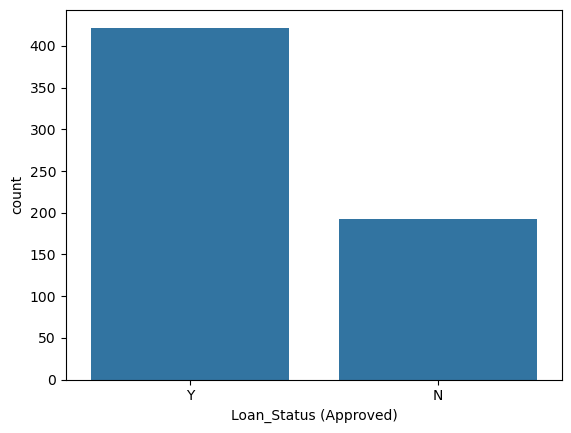

In [19]:
sns.countplot(x='Loan_Status (Approved)',data=df); plt.show()

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    object 
 1   Gender                  601 non-null    object 
 2   Married                 611 non-null    object 
 3   Dependents              599 non-null    object 
 4   Education               614 non-null    object 
 5   Self_Employed           582 non-null    object 
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              592 non-null    float64
 9   Loan_Amount_Term        600 non-null    float64
 10  Credit_History          564 non-null    float64
 11  Property_Area           614 non-null    object 
 12  Loan_Status (Approved)  614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [27]:
df.describe()


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [29]:
df.describe(include=object)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [31]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [33]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum()/len(df))*100
})
missing

,Missing Values,Percentage
Loan_ID,0,0.000000
Gender,13,2.117264
Married,3,0.488599
Dependents,15,2.442997
Education,0,0.000000
Self_Employed,32,5.211726
ApplicantIncome,0,0.000000
CoapplicantIncome,0,0.000000
LoanAmount,22,3.583062
Loan_Amount_Term,14,2.280130


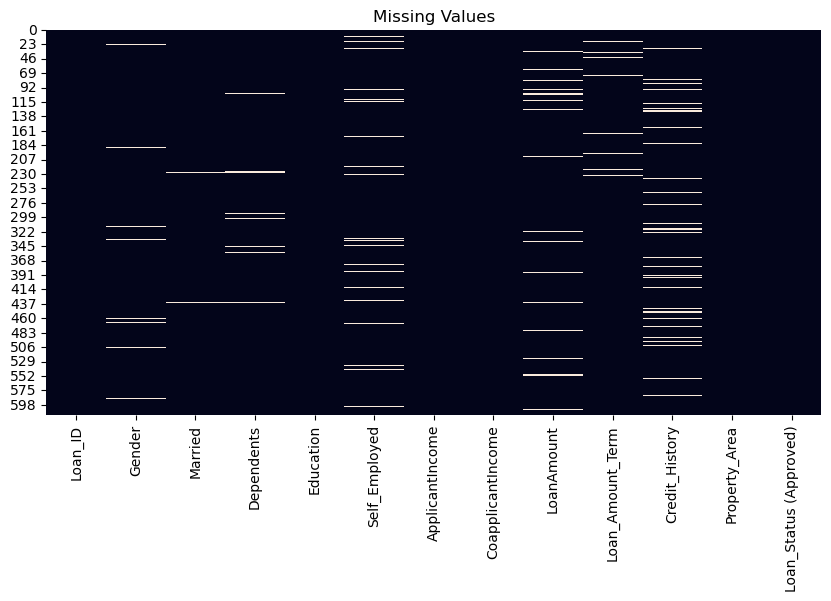

In [35]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()

In [37]:
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 0


In [ ]:
df = df.drop_duplicates()

In [39]:
# ==========================================
# Numerical and Categorical Columns
# ==========================================
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Numerical Columns")
print(numerical_cols)
print("\nCategorical Columns")
print(categorical_cols)

Numerical Columns
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical Columns
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status (Approved)']


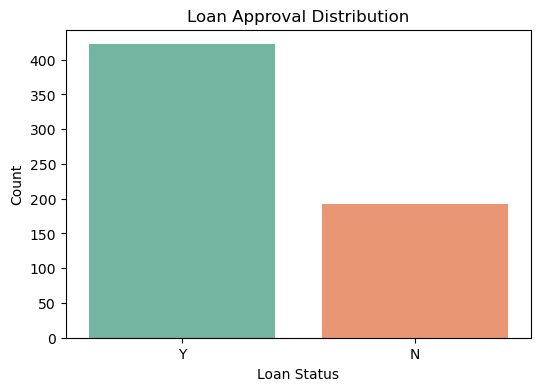

In [41]:
# ==========================================
# Target Variable Distribution
# ==========================================

plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x='Loan_Status (Approved)',
    palette='Set2'
)
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.show()

In [43]:
df["Loan_Status (Approved)"].value_counts(normalize=True)*100

Loan_Status (Approved)
Y    68.729642
N    31.270358
Name: proportion, dtype: float64

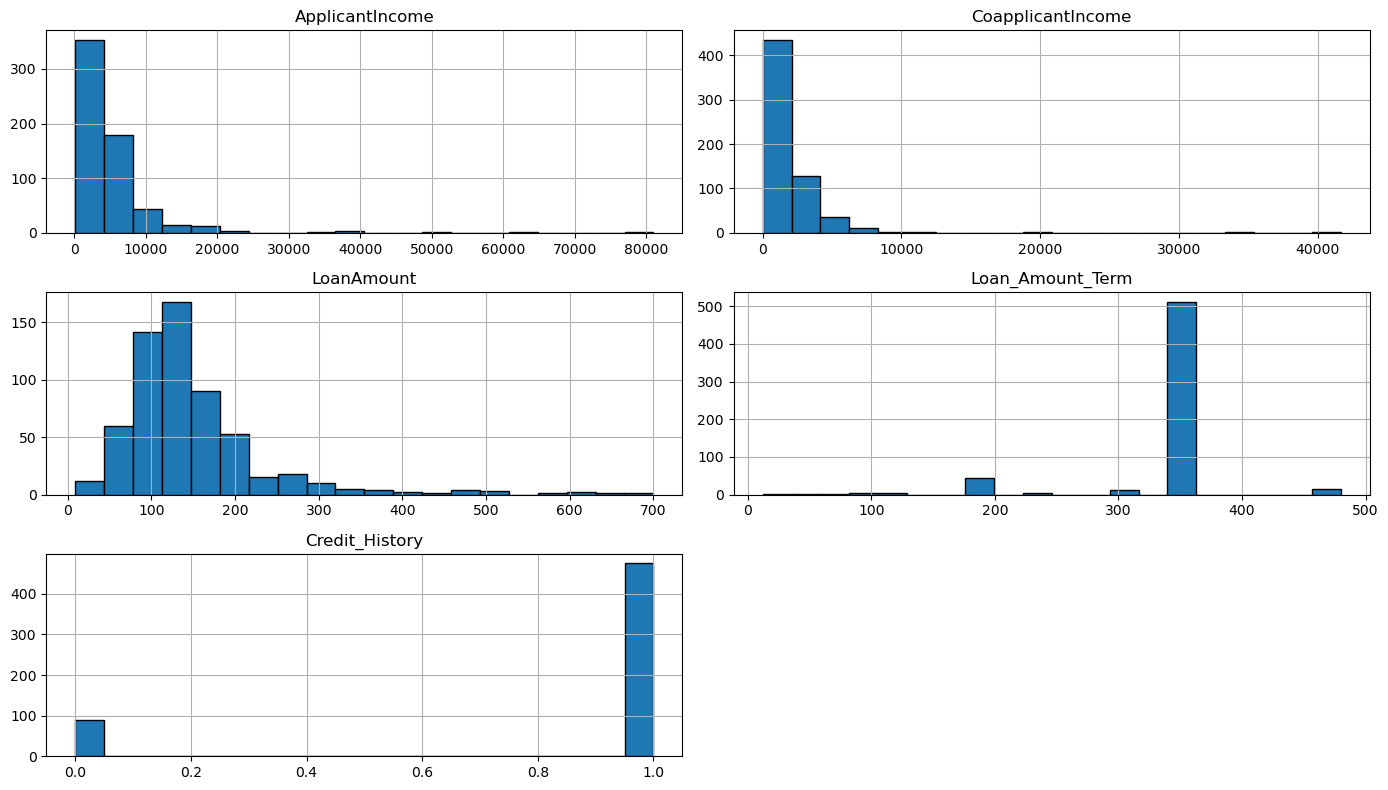

In [45]:
# ==========================================
# Histograms
# ==========================================
df[numerical_cols].hist(
    figsize=(14,8),
    bins=20,
    edgecolor="black"
)
plt.tight_layout()
plt.show()

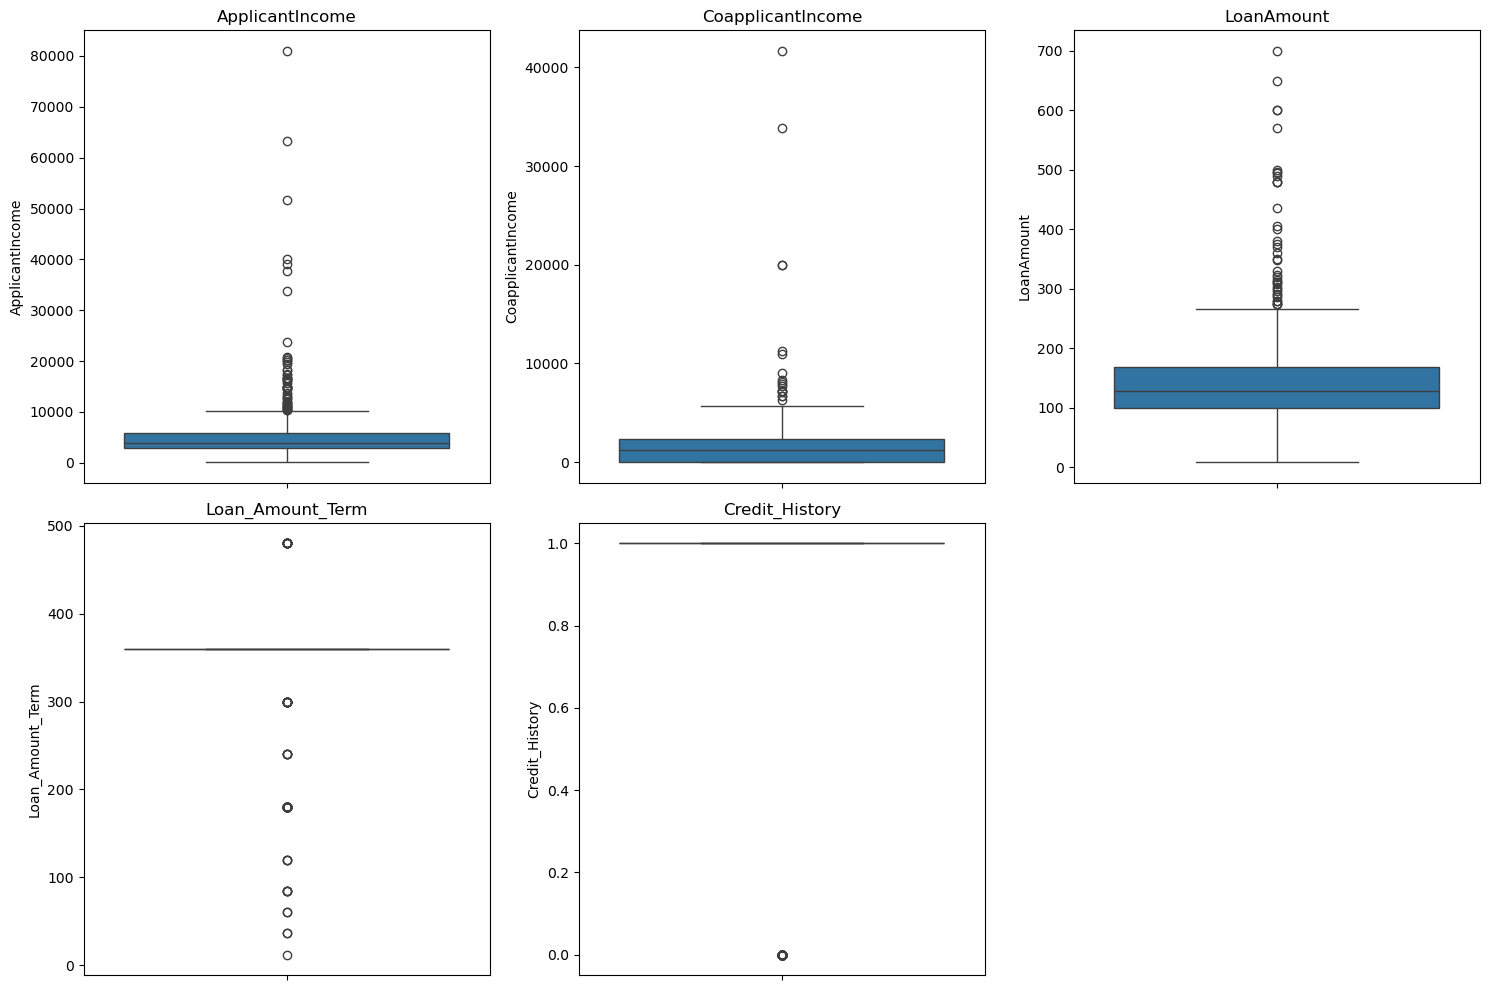

In [47]:
# ==========================================
# Boxplots
# ==========================================

plt.figure(figsize=(15,10))
for i, column in enumerate(numerical_cols):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

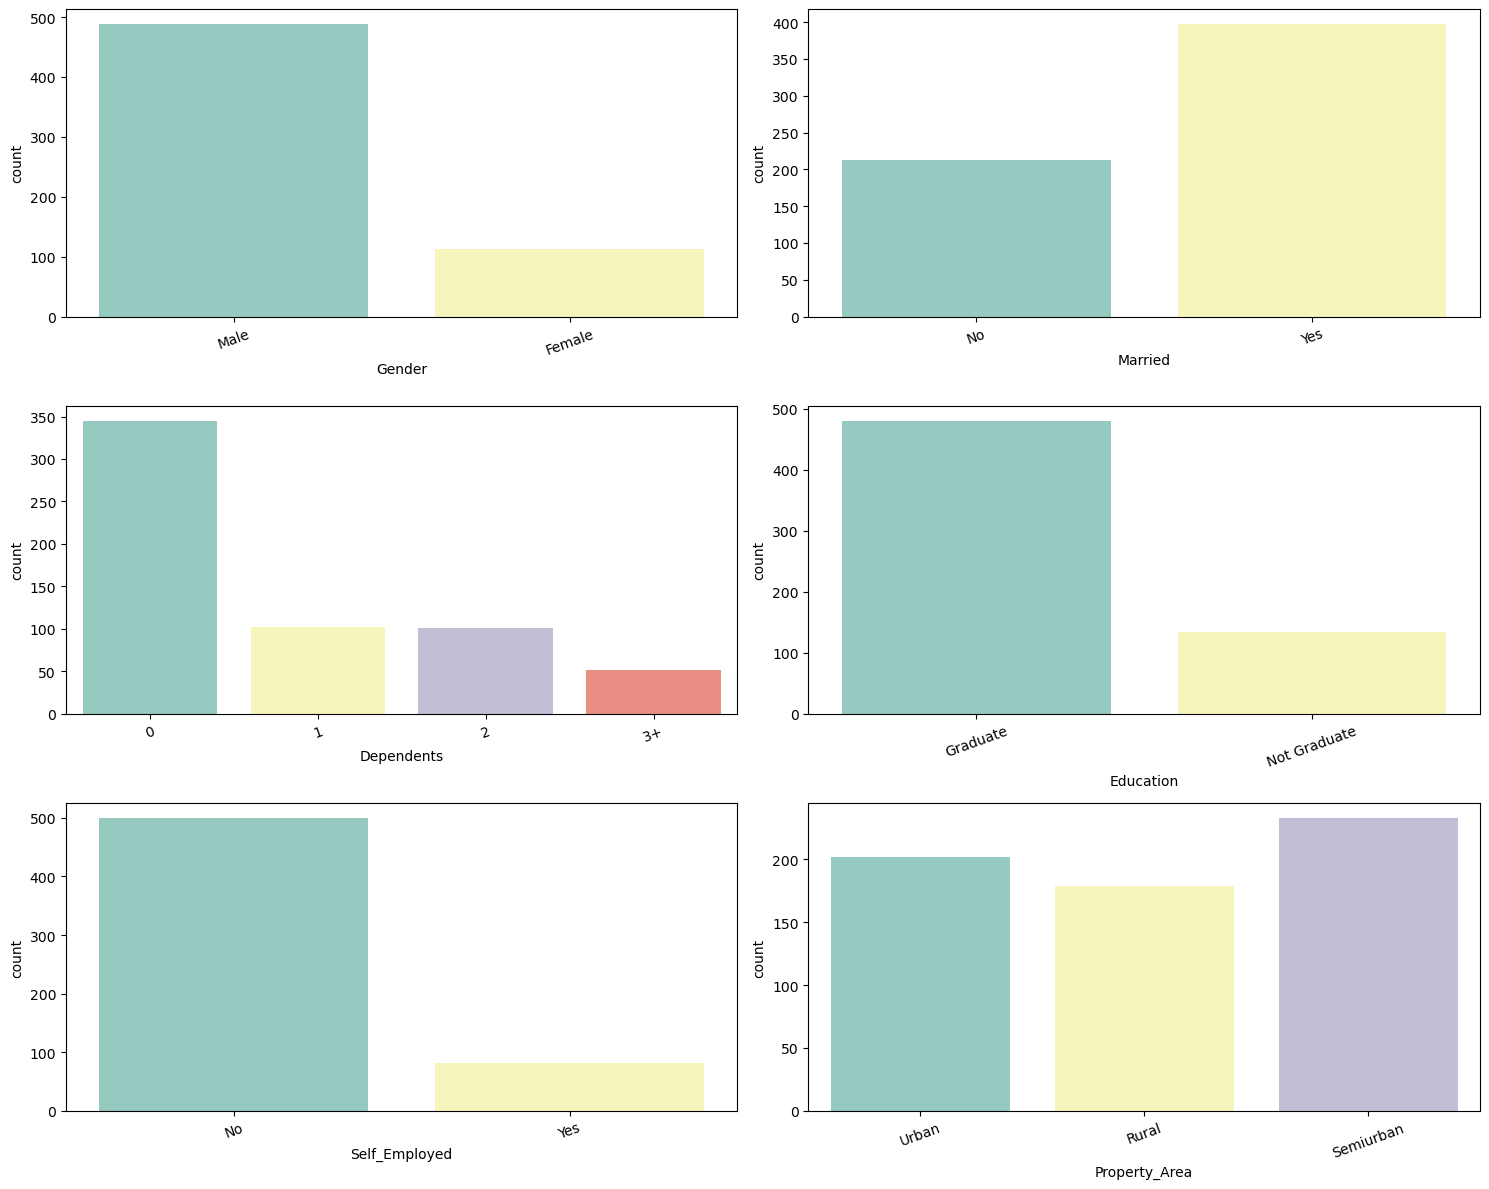

In [49]:
# ==========================================
# Countplots
# ==========================================
categorical_features = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area"
]
plt.figure(figsize=(15,12))
for i, column in enumerate(categorical_features):
    plt.subplot(3,2,i+1)
    sns.countplot(
        data=df,
        x=column,
        palette="Set3"
    )
    plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

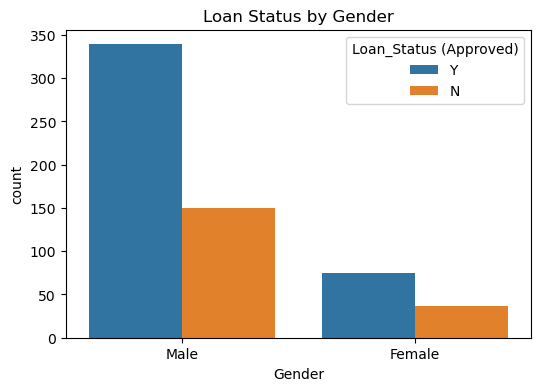

In [51]:
plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x="Gender",
    hue="Loan_Status (Approved)"
)
plt.title("Loan Status by Gender")
plt.show()

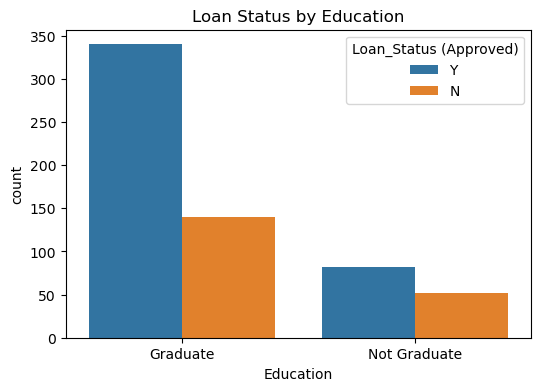

In [53]:
plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status (Approved)"
)
plt.title("Loan Status by Education")
plt.show()

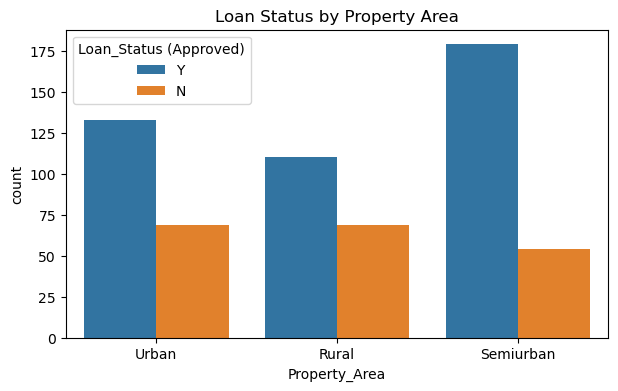

In [55]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=df,
    x="Property_Area",
    hue="Loan_Status (Approved)"
)

plt.title("Loan Status by Property Area")

plt.show()

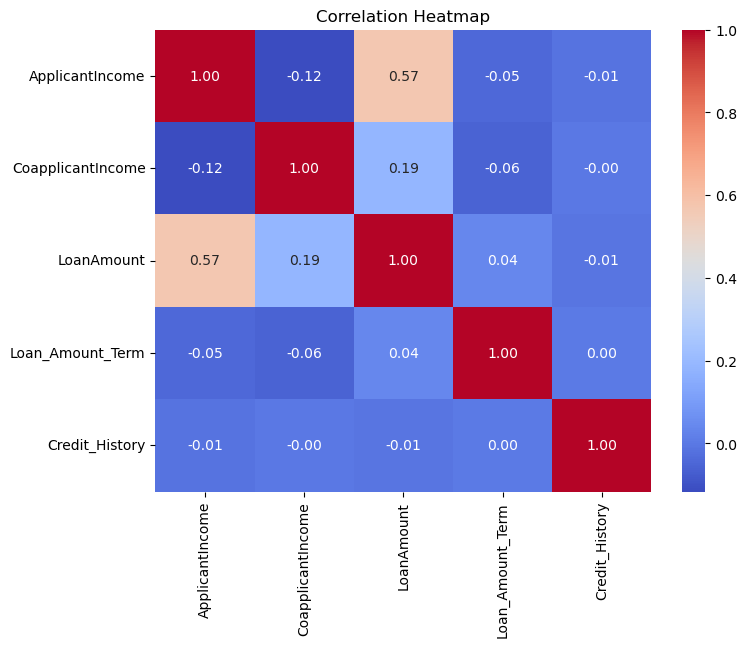

In [57]:
# ==========================================
# Correlation Heatmap
# ==========================================

plt.figure(figsize=(8,6))
sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

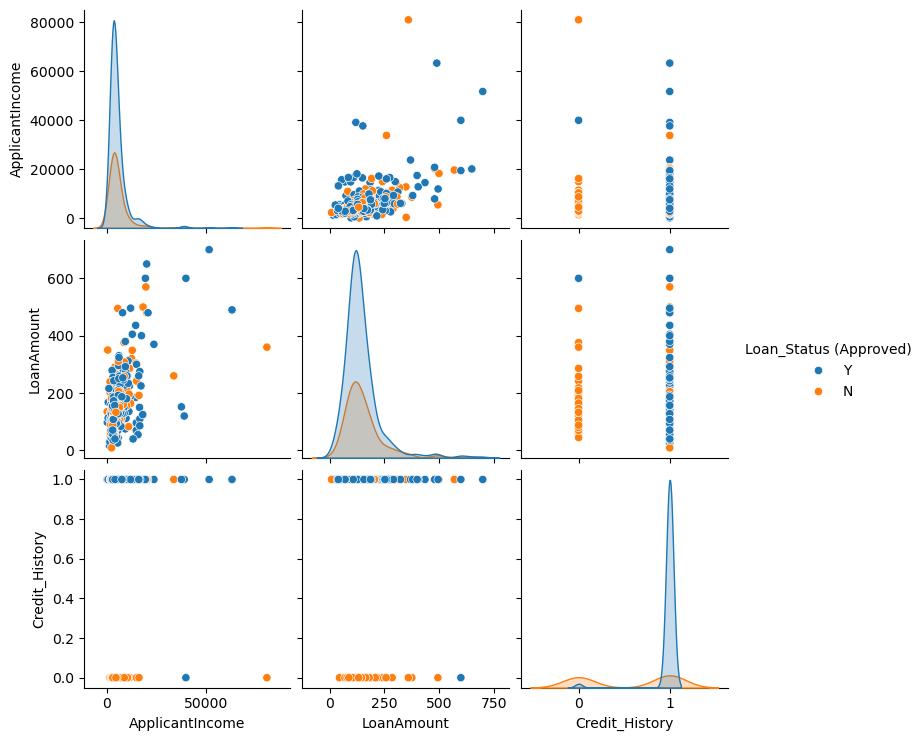

In [59]:
# ==========================================
# Pairplot
# ==========================================
selected_features = [
    "ApplicantIncome",
    "LoanAmount",
    "Credit_History",
    "Loan_Status (Approved)"
]
sns.pairplot(
    df[selected_features],
    hue="Loan_Status (Approved)"
)
plt.show()

In [61]:
# ==========================================
# Features and Target
# ==========================================

X = df.drop("Loan_Status (Approved)", axis=1)

y = df["Loan_Status (Approved)"]

print("Features Shape :", X.shape)
print("Target Shape :", y.shape)

Features Shape : (614, 12)
Target Shape : (614,)


In [63]:
y

0      Y
1      N
2      Y
3      Y
4      Y
      ..
609    Y
610    Y
611    Y
612    Y
613    N
Name: Loan_Status (Approved), Length: 614, dtype: object

In [65]:
# ==========================================
# Encode Target Variable
# ==========================================
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
print(label_encoder.classes_)

['N' 'Y']


In [67]:
y

array([1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0,

In [69]:
# ==========================================
# Feature Types
# ==========================================

ordinal_features = [
    "Dependents"
]
nominal_features = [
    "Gender",
    "Married",
    "Education",
    "Self_Employed",
    "Property_Area"
]
numerical_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History"
]
print("Ordinal Features")
print(ordinal_features)

print("\nNominal Features")
print(nominal_features)

print("\nNumerical Features")
print(numerical_features)

Ordinal Features
['Dependents']

Nominal Features
['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']

Numerical Features
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']


In [71]:
categorical_cols = X.select_dtypes(include="object").columns

numerical_cols = X.select_dtypes(exclude="object").columns

In [73]:
# ==========================================
# Numerical Pipeline
# ==========================================

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   
    ("scaler", StandardScaler())
])

In [75]:
# ==========================================
# Ordinal Pipeline
# ==========================================

ordinal_pipeline = Pipeline([   
    ("imputer", SimpleImputer(strategy="most_frequent")),   
    ("encoder",
     OrdinalEncoder(
         categories=[
             ["0","1","2","3+"]
         ]
     ))
])

In [77]:
# ==========================================
# Nominal Pipeline
# ==========================================

nominal_pipeline = Pipeline([  
    ("imputer",
     SimpleImputer(strategy="most_frequent")),  
    ("encoder",
     OneHotEncoder(handle_unknown="ignore"))
])

## Preprocessing

In [79]:
# ==========================================
# Column Transformer
# ==========================================

preprocessor = ColumnTransformer(   
    transformers=[       
        ("num",
         numerical_pipeline,
         numerical_features),     
        ("ord",
         ordinal_pipeline,
         ordinal_features),     
        ("nom",
         nominal_pipeline,
         nominal_features)  ])

In [81]:
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['ApplicantIncome', 'CoapplicantIncome',
                                  'LoanAmount', 'Loan_Amount_Term',
                                  'Credit_History']),
                                ('ord',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['0',
                                                                              '1',
                                                                              '2',
                                                                              '3+']]))]),
                                 ['Dependents']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Married', 'Education',
                                  'Self_Employed', 'Property_Area'])])

## Train/Test

In [83]:
# ==========================================
# Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.30, random_state=42,stratify=y)
print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

Training Shape : (429, 12)
Testing Shape : (185, 12)


In [115]:
print(len(y_train[ y_train > 0]))
print(len(y_train[ y_train == 0]))

295
134


In [117]:
print(len(y_test[ y_test > 0]))
print(len(y_test[ y_test == 0]))

127
58


In [119]:
# ==========================================
# Fit Preprocessor
# ==========================================
preprocessor.fit(X_train)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['ApplicantIncome', 'CoapplicantIncome',
                                  'LoanAmount', 'Loan_Amount_Term',
                                  'Credit_History']),
                                ('ord',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['0',
                                                                              '1',
                                                                              '2',
                                                                              '3+']]))]),
                                 ['Dependents']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Married', 'Education',
                                  'Self_Employed', 'Property_Area'])])

In [121]:
# ==========================================
# Save Transformer
# ==========================================

joblib.dump(
    preprocessor,
    "loan_preprocessor.pkl"
)

['loan_preprocessor.pkl']

## Save Transformer

In [124]:
# ==========================================
# Transform Data
# ==========================================
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [126]:
print("Original Training Shape")
print(X_train.shape)
print()
print("Processed Training Shape")
print(X_train_processed.shape)

Original Training Shape
(429, 12)

Processed Training Shape
(429, 17)


## Model

In [128]:
# ==========================================
# Build SVM Classifier
# ==========================================

svm_model = SVC( kernel="rbf",  C=1, gamma="scale")

svm_model.fit(X_train_processed, y_train
)
print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [130]:
# ==========================================
# Predict Test Data
# ==========================================
y_pred = svm_model.predict(X_test_processed)
print(y_pred[:20])

[1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1]


In [132]:
predictions = label_encoder.inverse_transform(y_pred)
predictions[:20]

array(['Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'N',
       'Y', 'Y', 'Y', 'Y', 'Y', 'Y', 'Y'], dtype=object)

In [134]:
y_test.shape

(185,)

In [136]:
y_pred.shape

(185,)

In [138]:
accuracy = accuracy_score(  
    y_test,  
    y_pred)
print(f"Accuracy : {accuracy:.4f}")

print(f"Accuracy : {accuracy*100:.2f}%")

Accuracy : 0.8432
Accuracy : 84.32%


In [140]:
cm = confusion_matrix(  
    y_test,
    y_pred
)
cm

array([[ 31,  27],
       [  2, 125]], dtype=int64)

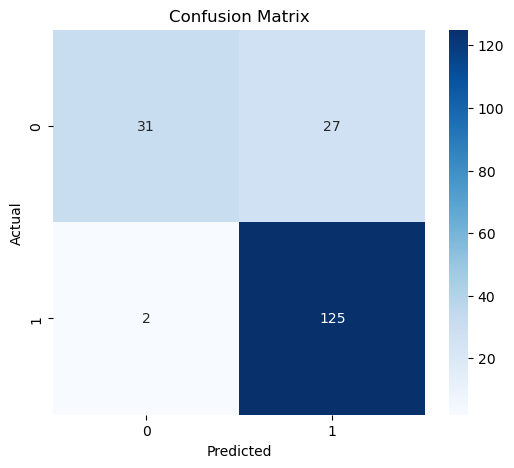

In [142]:
plt.figure(figsize=(6,5))

sns.heatmap(  
    cm,  
    annot=True,
    
    cmap="Blues",
    
    fmt="d"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

In [144]:
print(

classification_report(
    y_test,
    y_pred
)
)

              precision    recall  f1-score   support

           0       0.94      0.53      0.68        58
           1       0.82      0.98      0.90       127

    accuracy                           0.84       185
   macro avg       0.88      0.76      0.79       185
weighted avg       0.86      0.84      0.83       185



In [146]:
y_prob = svm_model.decision_function(  
    X_test_processed)

In [148]:
fpr, tpr, thresholds = roc_curve(   
    y_test,   
    y_prob
)

auc_score = roc_auc_score(
    
    y_test,
    
    y_prob
)

In [150]:
auc_score

0.8247352701601954

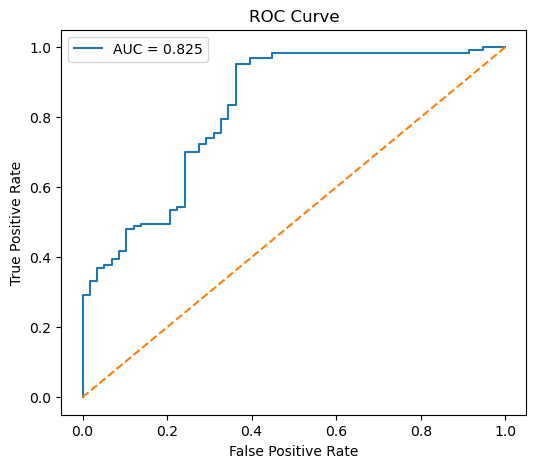

In [152]:
plt.figure(figsize=(6,5))

plt.plot( fpr,   tpr,  label=f"AUC = {auc_score:.3f}")
plt.plot(   [0,1], [0,1], 
    linestyle="--")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [156]:
joblib.dump(svm_model, "loan_svm.pkl")

['loan_svm.pkl']

In [ ]:
# Grid Search CV 

In [158]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score

In [160]:
params={'C':[0.1,1,10,15,35],'gamma':['scale',0.1,0.01,0.0005],'kernel':['linear','rbf','poly']}
grid=GridSearchCV(SVC(),params,cv=5)
grid.fit(X_train_processed,y_train)
best=grid.best_estimator_

In [162]:
best

SVC(C=0.1, kernel='linear')

## Evaluation

In [164]:
pred=best.predict(X_test_processed)
print(accuracy_score(y_test,pred))
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

0.8486486486486486
[[ 32  26]
 [  2 125]]
              precision    recall  f1-score   support

           0       0.94      0.55      0.70        58
           1       0.83      0.98      0.90       127

    accuracy                           0.85       185
   macro avg       0.88      0.77      0.80       185
weighted avg       0.86      0.85      0.84       185



## Save Model

In [ ]:
joblib.dump(best,'svm_model.pkl')

## Predict New

In [ ]:
prep=joblib.load('preprocessor.pkl')
model=joblib.load('svm_model.pkl')
# new=pd.DataFrame([...])
# model.predict(prep.transform(new))